# Paclitaxel single-cell exposure: GSE266934

**Question.** What cellular programs appear after exposure to a terpene-derived compound, and how do they vary with exposure time?

Paclitaxel is a **taxane diterpenoid**. This is a chemical-exposure single-cell RNA-seq analysis, **not genetic Perturb-seq**. It is relevant to terpene biology but cannot establish a response shared by other terpene classes.

**Primary sources:** [GEO GSE266934](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE266934), [study article](https://doi.org/10.1038/s41598-024-82218-9), [PubChem paclitaxel](https://pubchem.ncbi.nlm.nih.gov/compound/Paclitaxel). The public HCC1143 experiment compares 1 nM paclitaxel with 0.1% DMSO after 24 and 72 hours, with one filtered 10x library per arm and time point.

## Methods and provenance

The analysis downloads the four filtered gene-expression matrices from the GEO supplementary archive and checks its frozen SHA-256 digest. It retains cells with at least 3,000 detected genes, no more than 25% mitochondrial UMIs, and at least one UMI. Each cell gets the mean `log1p(count / total_UMIs × 10,000)` across a prespecified six-gene cell-cycle panel and seven-gene interferon panel. For each time point, the descriptive contrast is the treated minus control median panel score. Marker-level abundance is pooled UMIs per million UMIs in each library; the reported log2 ratio has a +1 CPM pseudocount.

This is **exploratory and descriptive**. One library per condition means cells cannot serve as biological replicates. Differences may reflect batch, cell composition, or differential survival. There are no p-values, confidence intervals, differential-expression claims, or target-dependency claims.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

repo = Path.cwd()
sys.path.insert(0, str(repo))
from research.transcriptomics.gse266934.analysis import analyze

result_dir = repo / "research/transcriptomics/gse266934/results"
summary = analyze(Path("/tmp/terputer-gse266934"), result_dir)
print("GEO:", summary["accession"], "| archive SHA-256:", summary["source_sha256"])
print("Independent libraries per condition:", summary["independent_libraries_per_condition"])

GEO: GSE266934 | archive SHA-256: 547370866041ae6048eed81a0d6486a5261ecc628d89956bdcca788a6c308ccc
Independent libraries per condition: 1


## Library quality control

In [2]:
display(pd.read_csv(result_dir / "library_qc.tsv", sep="\t"))

,sample,treatment,hours,filtered_matrix_cells,cells_after_qc,median_umis_after_qc,median_genes_after_qc,median_mito_fraction_after_qc
0,GSM8257022,DMSO,24,1191,1106,58257.5,7474.0,0.074918
1,GSM8257023,paclitaxel,24,950,788,57188.5,7206.5,0.069059
2,GSM8257024,DMSO,72,904,787,54013.0,6942.0,0.066616
3,GSM8257025,paclitaxel,72,676,513,56858.0,7223.0,0.063885


## Time-matched marker programs

,hours,treatment,panel,cells,median,q25,q75
0,24,DMSO,cell_cycle,1106,0.769,0.514,1.074
1,24,DMSO,interferon,1106,0.203,0.156,0.259
2,24,paclitaxel,cell_cycle,788,0.519,0.191,0.864
3,24,paclitaxel,interferon,788,0.422,0.265,0.616
4,72,DMSO,cell_cycle,787,0.292,0.083,0.728
5,72,DMSO,interferon,787,0.289,0.203,0.377
6,72,paclitaxel,cell_cycle,513,0.242,0.113,0.524
7,72,paclitaxel,interferon,513,0.799,0.577,1.042


,hours,panel,paclitaxel_minus_DMSO_median,paclitaxel_median,DMSO_median,interpretation
0,24,cell_cycle,-0.251,0.519,0.769,descriptive; one library per condition
1,24,interferon,0.218,0.422,0.203,descriptive; one library per condition
2,72,cell_cycle,-0.049,0.242,0.292,descriptive; one library per condition
3,72,interferon,0.510,0.799,0.289,descriptive; one library per condition


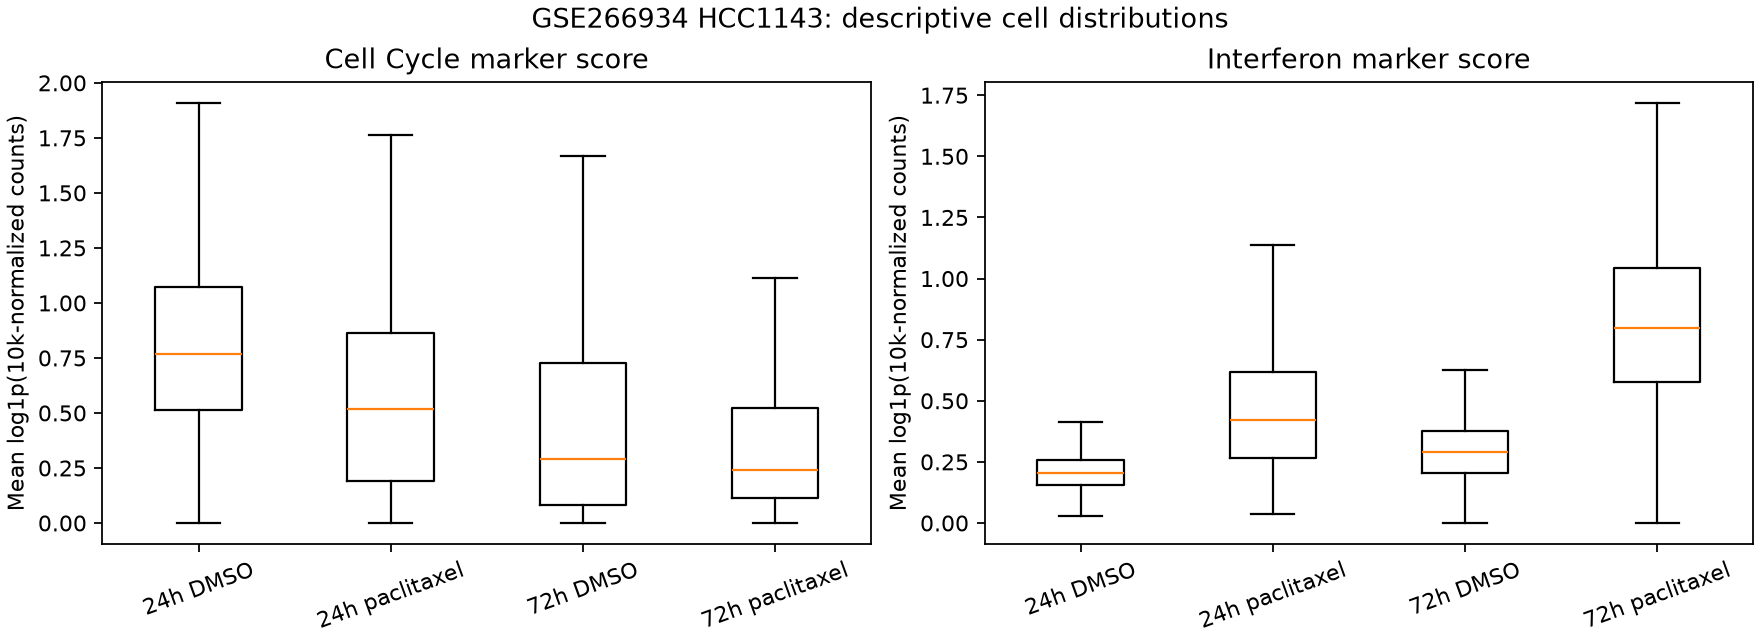

In [3]:
display(pd.read_csv(result_dir / "module_summary.tsv", sep="\t").round(3))
display(pd.read_csv(result_dir / "module_contrasts.tsv", sep="\t").round(3))
display(Image(filename=str(result_dir / "marker_scores.png")))

## Gene-level descriptive abundance

In [4]:
markers = pd.read_csv(result_dir / "marker_cpm_ratios.tsv", sep="\t")
display(markers.pivot(index=["panel", "gene"], columns="hours", values="descriptive_log2_CPM_ratio").round(2))

hours               24    72
panel      gene             
cell_cycle CCNB1  0.35  0.65
           CDK1  -0.37 -0.14
           CENPF -0.50 -0.85
           MKI67 -0.84 -0.70
           TOP2A -0.49 -0.68
           UBE2C  0.22  0.54
interferon IFI6   2.37  3.29
           IFIT1  2.25  3.26
           IFIT3  0.61  3.60
           ISG15  1.60  2.71
           MX1    0.35  1.08
           OAS1   2.28  2.94
           STAT1  0.89  1.22

## Interpretation

The interferon panel is higher in paclitaxel cells at both 24 and 72 hours, with a larger median separation at 72 hours. The selected cell-cycle panel is lower in treated cells at both times, although the marker-level ratios are mixed: `CCNB1` and `UBE2C` are higher while `MKI67`, `TOP2A`, and `CENPF` are lower. These patterns are **within this HCC1143 model and dose only**. The experiment does not support claims of cross-cell-type reproducibility, shared effects across terpenes, or specific target mediation.

**Next experiment:** repeat these four arms across at least three independent culture preparations, randomize library preparation, add a second dose, and compare paclitaxel with a chemically distinct terpenoid. For target-dependence, pair exposure with an independently replicated target perturbation. Use library-level or replicate-level inference after collecting those data.